# R2 – Data Description & Analysis
**F20DL Group 15 · Data lead: Abdullah Shaikh**

This notebook documents the dataset the whole group uses and explores it before any modelling.

1. Dataset: source, licence, collection method
2. Download & cleaning pipeline (what was removed and why)
3. Class balance and the shared train / val / test split
4. Skin-tone (Fitzpatrick) distribution
5. Example images
6. Image summary statistics (size, colour, brightness)
7. Preprocessing used by every model
8. Unsupervised analysis: k-means clustering
9. Key findings (numbers for the report)

Every figure is also saved to `documentation/figures/` so it can go straight into the report.

**Needs:** `pip install numpy pillow pandas matplotlib scikit-learn ipykernel`

In [1]:
# ---------------------------------------------------------------- setup ---
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Find the processed data folder. Works for the repo layout (unzipped into the repo
# root) and for a notebook sitting next to the folder.
CANDIDATES = ["../Fitzpatrick17k_processed", "../../Fitzpatrick17k_processed",
              "Fitzpatrick17k_processed"]
DATA_DIR = next((p for p in CANDIDATES if os.path.exists(os.path.join(p, "dataset.csv"))), None)
assert DATA_DIR, "Can't find Fitzpatrick17k_processed - unzip the OneDrive zip into the repo folder"

# Original Fitzpatrick17k CSVs (in the repo's data/ folder) - used to measure what we lost
RAW_CANDIDATES = ["../data", "data", DATA_DIR]
RAW_DIR = next((p for p in RAW_CANDIDATES
                if os.path.exists(os.path.join(p, "psoriasis.csv"))), None)

FIG_DIR = "../documentation/figures"
os.makedirs(FIG_DIR, exist_ok=True)

sys.path.append(DATA_DIR)
from load_data import load_split, load_info, CLASS_NAMES   # the group's shared loader

SEED = 42

# One fixed colour per disease, used in every chart (colour-blind-safe palette)
COLOURS = {"allergic contact dermatitis": "#2a78d6", "basal cell carcinoma": "#eb6834",
           "psoriasis": "#1baf7a", "seborrheic dermatitis": "#eda100", "vitiligo": "#e87ba4"}
SHORT = {"allergic contact dermatitis": "Contact dermatitis", "basal cell carcinoma": "Basal cell carcinoma",
         "psoriasis": "Psoriasis", "seborrheic dermatitis": "Seborrheic dermatitis", "vitiligo": "Vitiligo"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "font.size": 10})


def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")


df = pd.read_csv(os.path.join(DATA_DIR, "dataset.csv"))
print("Data folder :", os.path.abspath(DATA_DIR))
print("Raw CSVs    :", os.path.abspath(RAW_DIR) if RAW_DIR else "not found (section 2 will be skipped)")
print("Images      :", len(df))
print("Versions    : numpy", np.__version__, "| pandas", pd.__version__)
df.head()

Data folder : d:\Downloads\Study and Work\Heriot Watt\Year 4\Data Mining Machine Learning\Datasets\Fitzpatrick17k_processed
Raw CSVs    : d:\Downloads\Study and Work\Heriot Watt\Year 4\Data Mining Machine Learning\Datasets\Github Repo\data
Images      : 1623
Versions    : numpy 2.5.5 | pandas 3.1.1


,file,label,label_id,is_malignant,fitzpatrick_scale,source_folder,md5hash,split
0,images/allergic_contact_dermatitis/allergic_co...,allergic contact dermatitis,0,0,3,allergic_contact_dermatitis,09d46db9589ff45436cda87c4abc946b,train
1,images/allergic_contact_dermatitis/allergic_co...,allergic contact dermatitis,0,0,1,rhus_dermatitis,890cf5d791c7e738d156ec3ea95fae5d,val
2,images/allergic_contact_dermatitis/allergic_co...,allergic contact dermatitis,0,0,2,allergic_contact_dermatitis,56e697186c86b0eb09f19021ebe4b9a8,train
3,images/allergic_contact_dermatitis/allergic_co...,allergic contact dermatitis,0,0,1,patch-testing,7e8285c87bf045d7eb75042155632036,train
4,images/allergic_contact_dermatitis/allergic_co...,allergic contact dermatitis,0,0,3,allergic_contact_dermatitis,1eb2cf388f9b1ab6b98056d81b1e6faf,train


## 1. Dataset: source, licence, collection

| | |
|---|---|
| **Dataset** | Fitzpatrick17k (Groh et al., 2021): 16,577 clinical images of 114 skin conditions |
| **Our subset** | 5 conditions chosen at the pitch: allergic contact dermatitis, basal cell carcinoma, psoriasis, seborrheic dermatitis, vitiligo |
| **Source** | https://github.com/mattgroh/fitzpatrick17k |
| **Licence** | Creative Commons Attribution-NonCommercial-ShareAlike 3.0 (CC BY-NC-SA 3.0): free for non-commercial use with attribution |
| **Collection method** | Images come from two online dermatology atlases, **DermaAmin** and **Atlas Dermatologico**, together with the atlas's condition label. Each image was then annotated with a **Fitzpatrick skin type** (I = very light … VI = very dark) by two data-annotation services (Scale AI and Centaur Labs). |
| **Access** | The CSV only stores image URLs; images must be downloaded from the atlases (`scripts/download_images.py`). |

**Columns we use (`dataset.csv`)**

| Column | Meaning |
|---|---|
| `file` | path to the cleaned image |
| `label`, `label_id` | the disease (target for all models), 0–4 |
| `is_malignant` | 1 = basal cell carcinoma (cancer), 0 = not cancer (for the binary task) |
| `fitzpatrick_scale` | skin type 1–6 (−1 = not annotated) |
| `source_folder` | the atlas folder the image came from (used to find mislabelled images) |
| `split` | train / val / test, the same for everyone |

The model inputs themselves are the **image pixels** (RGB), so the "features" are colour values at each position.

**Why this dataset:** it is one of very few public dermatology datasets with skin-type labels, so we can check how well light and dark skin are represented, a known problem for medical AI. The photos are ordinary clinical photographs, not dermoscopy images.

**Reference:** M. Groh, C. Harris, L. Soenksen, F. Lau, R. Han, A. Kim, A. Koochek, O. Badri. *Evaluating Deep Neural Networks Trained on Clinical Images in Dermatology with the Fitzpatrick 17k Dataset.* CVPR Workshops (ISIC), 2021.

## 2. Download & cleaning pipeline

**Download (`download_images.py`).** About 73% of the CSV links pointed at DermaAmin's old website, which now returns 404 for every image. DermaAmin moved to a new site that keeps the same file names, so the script rewrites each dead link to the new address. Atlas Dermatologico links worked as-is.

**Cleaning (`clean_and_split.py`).**
1. **Wrong disease in source folder:** the atlas folder name shows what an image really is. Images from folders of a *different* disease were removed (e.g. *Grover's disease* labelled as contact dermatitis, *parapsoriasis* and *filariasis* labelled as psoriasis, *seborrhoeic warts* labelled as seborrheic dermatitis).
2. **Dataset quality control:** images the dataset itself flags as "wrongly labelled" were removed.
3. **Unreadable or tiny files:** removed (none found).
4. **Duplicates:** near-identical photos were found with a 256-bit perceptual hash *and* confirmed pixel-by-pixel; one copy was kept. This stops the same photo ending up in both training and testing (data leakage).

In [2]:
# How many images were listed, downloaded, removed and kept - per disease
removed = pd.read_csv(os.path.join(DATA_DIR, "removed_images.csv"))
removed["reason_group"] = removed["reason"].str.split(" \\(").str[0]

final_counts = df["label"].value_counts()
removed_counts = removed.groupby("label").size()

if RAW_DIR:
    raw = pd.concat([pd.read_csv(os.path.join(RAW_DIR, f"{name.replace(' ', '_')}.csv"))
                     for name in CLASS_NAMES])
    listed = raw["label"].value_counts()
    funnel = pd.DataFrame({"listed in CSV": listed,
                           "downloaded": final_counts.add(removed_counts, fill_value=0).astype(int),
                           "removed in cleaning": removed_counts.reindex(listed.index, fill_value=0),
                           "final": final_counts})
    funnel["% of listed kept"] = (100 * funnel["final"] / funnel["listed in CSV"]).round(1)
    funnel.loc["TOTAL"] = funnel.sum(numeric_only=True)
    funnel.loc["TOTAL", "% of listed kept"] = round(100 * funnel.loc["TOTAL", "final"]
                                                    / funnel.loc["TOTAL", "listed in CSV"], 1)
    display(funnel.astype({c: int for c in funnel.columns[:4]}))

print("\nWhy images were removed:")
display(removed["reason_group"].value_counts().rename("images").to_frame())

wrong = removed[removed["reason_group"] == "wrong disease in source folder"]
if len(wrong):
    folders = wrong["reason"].str.extract(r"\((.*)\)")[0]
    print("Mislabelled source folders removed:")
    display(pd.crosstab(folders, wrong["label"]))

df["source_site"] = np.where(df["source_folder"] == "atlasdermatologico", "Atlas Dermatologico", "DermaAmin")
src = pd.crosstab(df["label"].map(SHORT), df["source_site"])
src["% from Atlas"] = (100 * src.get("Atlas Dermatologico", 0) / src.sum(axis=1)).round(1)
print("\nFinal images by source atlas:")
display(src)

,listed in CSV,downloaded,removed in cleaning,final,% of listed kept
label,,,,,
allergic contact dermatitis,430,394,13,381,88.6
basal cell carcinoma,468,355,0,355,75.9
psoriasis,653,635,31,604,92.5
seborrheic dermatitis,126,124,1,123,97.6
vitiligo,166,161,1,160,96.4
TOTAL,1843,1669,46,1623,88.1



Why images were removed:


,images
reason_group,
wrong disease in source folder,39
duplicate of another image,6
dataset QC: wrongly labelled,1


Mislabelled source folders removed:


label,allergic contact dermatitis,psoriasis,seborrheic dermatitis
0,,,
grovers_disease_transient_acantholytic_dermatosis,6,0,0
oxyuriasis,0,1,0
parapsoriasis-en-goutte,0,3,0
parapsoriasis-large-plaque,0,19,0
parapsoriasis-small-plaque-type,0,3,0
salmon-patches,6,0,0
seborrhoeic-warts,0,0,1



Final images by source atlas:


source_site,Atlas Dermatologico,DermaAmin,% from Atlas
label,,,
Basal cell carcinoma,257,98,72.4
Contact dermatitis,43,338,11.3
Psoriasis,104,500,17.2
Seborrheic dermatitis,49,74,39.8
Vitiligo,43,117,26.9


**Source bias check.** Every Atlas Dermatologico photo carries a small **"SFS" watermark** in the bottom-left corner (visible in section 5). If one disease comes mostly from Atlas and another mostly from DermaAmin, a model could learn *"watermark → that disease"* instead of the skin itself, a known shortcut-learning risk. The table above shows how uneven the sources are per disease. We report this as a limitation; a possible mitigation is cropping the image borders.

## 3. Class balance and the shared split

All models use **one split**, made once in `clean_and_split.py`: stratified by disease, 70 / 15 / 15, seed 42. *Stratified* means every disease appears in the same proportion in train, val and test.

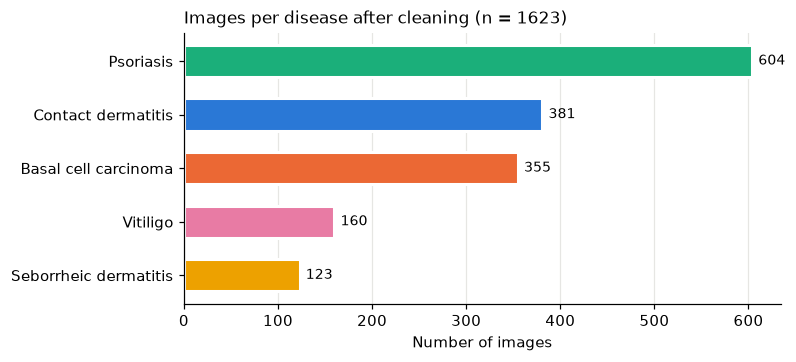

Imbalance: largest class is 4.9x the smallest (Psoriasis 604 vs Seborrheic dermatitis 123)
-> we use macro-F1 as the main metric and class weights, so small classes count equally.

Images per split:


split,train,val,test
label,,,
allergic contact dermatitis,267,57,57
basal cell carcinoma,248,53,54
psoriasis,423,91,90
seborrheic dermatitis,86,18,19
vitiligo,112,24,24
TOTAL,1136,243,244


Share of each split (%) - near-identical columns = stratification worked:


split,train,val,test
label,,,
allergic contact dermatitis,23.5,23.5,23.4
basal cell carcinoma,21.8,21.8,22.1
psoriasis,37.2,37.4,36.9
seborrheic dermatitis,7.6,7.4,7.8
vitiligo,9.9,9.9,9.8


In [3]:
counts = df["label"].value_counts().reindex(CLASS_NAMES)
order = counts.sort_values().index          # smallest at the bottom of the chart

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh([SHORT[c] for c in order], counts[order],
               color=[COLOURS[c] for c in order], height=0.6, edgecolor="white", linewidth=2)
ax.bar_label(bars, padding=4, fontsize=9)
ax.set_xlabel("Number of images")
ax.set_title("Images per disease after cleaning (n = %d)" % len(df), loc="left", fontsize=11)
ax.xaxis.grid(True, color="#e6e6e3"); ax.set_axisbelow(True)
save(fig, "r2_class_counts.png"); plt.show()

ratio = counts.max() / counts.min()
print(f"Imbalance: largest class is {ratio:.1f}x the smallest "
      f"({SHORT[counts.idxmax()]} {counts.max()} vs {SHORT[counts.idxmin()]} {counts.min()})")
print("-> we use macro-F1 as the main metric and class weights, so small classes count equally.\n")

split_table = pd.crosstab(df["label"], df["split"])[["train", "val", "test"]]
split_table.loc["TOTAL"] = split_table.sum()
share = (100 * pd.crosstab(df["label"], df["split"], normalize="columns"))[["train", "val", "test"]].round(1)
print("Images per split:")
display(split_table)
print("Share of each split (%) - near-identical columns = stratification worked:")
display(share)

## 4. Skin-tone (Fitzpatrick) distribution

Fitzpatrick skin type runs from **I (very light)** to **VI (very dark)**. If one skin type is rare, models may perform worse on it, so this matters for interpreting results.

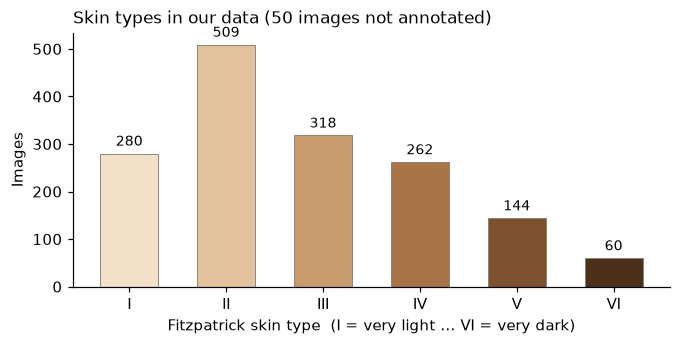

                   % of annotated images
fitzpatrick_scale                       
Light (I-II)                        50.2
Medium (III-IV)                     36.9
Dark (V-VI)                         13.0


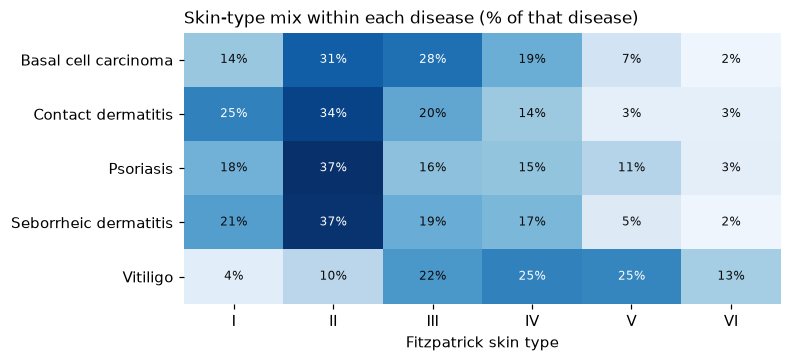

In [4]:
fitz = df["fitzpatrick_scale"]
known = df[fitz > 0]
tone_counts = known["fitzpatrick_scale"].value_counts().sort_index()

# sequential single-hue ramp: light type -> light bar, dark type -> dark bar
ramp = ["#f3e0c9", "#e2c19c", "#c99a6e", "#a87448", "#7c512d", "#4d3019"]
fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.bar(["I", "II", "III", "IV", "V", "VI"][:len(tone_counts)], tone_counts.values,
              color=ramp[:len(tone_counts)], width=0.6, edgecolor="#8a7f74", linewidth=0.6)
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_xlabel("Fitzpatrick skin type  (I = very light ... VI = very dark)")
ax.set_ylabel("Images")
ax.set_title(f"Skin types in our data ({(fitz <= 0).sum()} images not annotated)", loc="left", fontsize=11)
save(fig, "r2_skin_types.png"); plt.show()

groups = pd.cut(known["fitzpatrick_scale"], [0, 2, 4, 6], labels=["Light (I-II)", "Medium (III-IV)", "Dark (V-VI)"])
print((100 * groups.value_counts(normalize=True)).round(1).rename("% of annotated images").to_frame())

# Skin type by disease (% of each disease's images)
tab = pd.crosstab(known["label"].map(SHORT), known["fitzpatrick_scale"], normalize="index") * 100
fig, ax = plt.subplots(figsize=(7, 3.2))
im = ax.imshow(tab.values, cmap="Blues", vmin=0, aspect="auto")
ax.set_xticks(range(tab.shape[1]), ["I", "II", "III", "IV", "V", "VI"][:tab.shape[1]])
ax.set_yticks(range(tab.shape[0]), tab.index)
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]):
        v = tab.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=8,
                color="white" if v > tab.values.max() * 0.6 else "#0b0b0b")
ax.set_xlabel("Fitzpatrick skin type")
ax.set_title("Skin-type mix within each disease (% of that disease)", loc="left", fontsize=11)
ax.spines[:].set_visible(False)
save(fig, "r2_skin_type_by_disease.png"); plt.show()

## 5. Example images

Random training images for each disease (centre-cropped to a square, as the models see them).

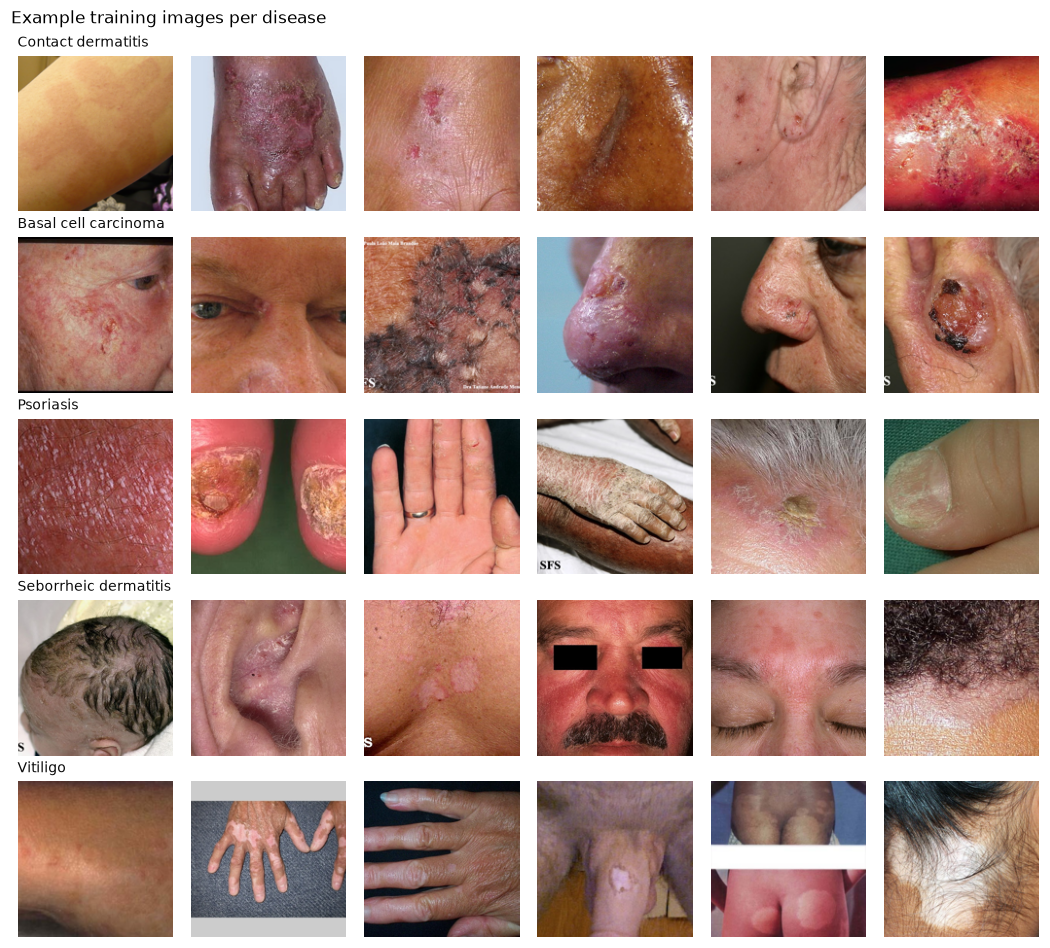

In [5]:
def square(im):
    w, h = im.size; s = min(w, h)
    return im.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s))

n_cols = 6
train = df[df["split"] == "train"]
fig, axes = plt.subplots(len(CLASS_NAMES), n_cols, figsize=(n_cols * 1.6, len(CLASS_NAMES) * 1.75))
for r, label in enumerate(CLASS_NAMES):
    pool = train[train["label"] == label]
    sample = pool.sample(min(n_cols, len(pool)), random_state=SEED)
    for c in range(n_cols):
        ax = axes[r, c]; ax.axis("off")
        if c < len(sample):
            with Image.open(os.path.join(DATA_DIR, sample.iloc[c]["file"])) as im:
                ax.imshow(square(im.convert("RGB")).resize((160, 160)))
    axes[r, 0].set_title(SHORT[label], loc="left", fontsize=9, color="#0b0b0b")
fig.suptitle("Example training images per disease", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
save(fig, "r2_examples.png"); plt.show()

## 6. Image summary statistics

**Size:** the original photos come in different sizes and shapes, which is why every image must be cropped and resized before modelling.
**Colour:** mean red/green/blue and brightness per image, computed at 64×64 (same crop as the models).

Original image size (pixels):


,mean,std,min,50%,max
width,503.7,226.0,119.0,462.0,2292.0
height,447.5,229.9,130.0,391.0,3240.0
aspect,1.2,0.3,0.3,1.2,3.2


Colour statistics per disease (pixel values scaled 0-1):


mean_R        mean_G        mean_B        brightness  \
                        mean    std   mean    std   mean    std       mean   
label                                                                        
Contact dermatitis     0.643  0.121  0.486  0.108  0.439  0.112      0.522   
Basal cell carcinoma   0.668  0.100  0.485  0.087  0.411  0.092      0.521   
Psoriasis              0.614  0.122  0.469  0.104  0.425  0.116      0.503   
Seborrheic dermatitis  0.638  0.098  0.457  0.072  0.407  0.079      0.501   
Vitiligo               0.581  0.116  0.444  0.098  0.387  0.099      0.471   

                             contrast         
                         std     mean    std  
label                                         
Contact dermatitis     0.105    0.166  0.067  
Basal cell carcinoma   0.085    0.119  0.050  
Psoriasis              0.105    0.164  0.060  
Seborrheic dermatitis  0.075    0.143  0.061  
Vitiligo               0.094    0.184  0.062

C:\Users\abd12\AppData\Local\Temp\ipykernel_34836\270335052.py:31: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  b = axes[0].boxplot(data, vert=False, patch_artist=True, widths=0.55,


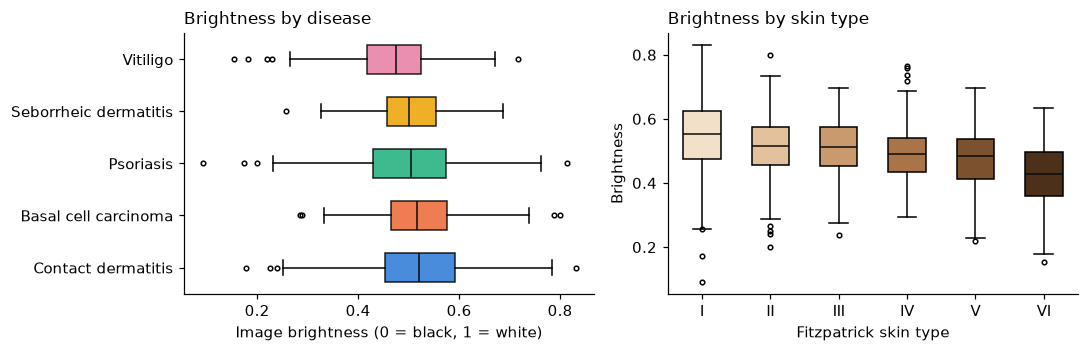

Correlation between skin type and brightness: r = -0.25 (weak).
-> brightness depends on more than skin tone (lighting, camera, body site).


In [6]:
# --- original image sizes (reads only the file header, fast) ---
sizes = []
for f in df["file"]:
    with Image.open(os.path.join(DATA_DIR, f)) as im:
        sizes.append(im.size)
df["width"], df["height"] = zip(*sizes)
df["aspect"] = (df["width"] / df["height"]).round(2)
print("Original image size (pixels):")
display(df[["width", "height", "aspect"]].describe().round(1).T[["mean", "std", "min", "50%", "max"]])

# --- colour statistics, using the shared loader (same preprocessing the models get) ---
parts = []
for s in ["train", "val", "test"]:
    X, _ = load_split(s, size=64)
    parts.append((X, pd.DataFrame(load_info(s))))
X64 = np.concatenate([p[0] for p in parts])
meta = pd.concat([p[1] for p in parts], ignore_index=True)
meta["fitzpatrick_scale"] = meta["fitzpatrick_scale"].astype(int)

meta["mean_R"], meta["mean_G"], meta["mean_B"] = (X64[..., k].mean(axis=(1, 2)) for k in range(3))
meta["brightness"] = X64.mean(axis=(1, 2, 3))              # 0 = black, 1 = white
meta["contrast"] = X64.mean(axis=-1).std(axis=(1, 2))      # spread of light/dark within an image

stats = meta.groupby("label")[["mean_R", "mean_G", "mean_B", "brightness", "contrast"]].agg(["mean", "std"]).round(3)
stats.index = stats.index.map(SHORT)
print("Colour statistics per disease (pixel values scaled 0-1):")
display(stats)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
data = [meta.loc[meta["label"] == c, "brightness"] for c in CLASS_NAMES]
b = axes[0].boxplot(data, vert=False, patch_artist=True, widths=0.55,
                    medianprops={"color": "#0b0b0b"}, flierprops={"markersize": 3})
for patch, c in zip(b["boxes"], CLASS_NAMES):
    patch.set_facecolor(COLOURS[c]); patch.set_alpha(0.85)
axes[0].set_yticks(range(1, len(CLASS_NAMES) + 1), [SHORT[c] for c in CLASS_NAMES])
axes[0].set_xlabel("Image brightness (0 = black, 1 = white)")
axes[0].set_title("Brightness by disease", loc="left", fontsize=11)

known_m = meta[meta["fitzpatrick_scale"] > 0]
types = sorted(known_m["fitzpatrick_scale"].unique())
b2 = axes[1].boxplot([known_m.loc[known_m["fitzpatrick_scale"] == t, "brightness"] for t in types],
                     patch_artist=True, widths=0.55, medianprops={"color": "#0b0b0b"},
                     flierprops={"markersize": 3})
for patch, t in zip(b2["boxes"], types):
    patch.set_facecolor(ramp[t - 1])
axes[1].set_xticks(range(1, len(types) + 1), ["I", "II", "III", "IV", "V", "VI"][:len(types)])
axes[1].set_xlabel("Fitzpatrick skin type"); axes[1].set_ylabel("Brightness")
axes[1].set_title("Brightness by skin type", loc="left", fontsize=11)
fig.tight_layout(); save(fig, "r2_brightness.png"); plt.show()

r = np.corrcoef(known_m["fitzpatrick_scale"], known_m["brightness"])[0, 1]
strength = "strong" if abs(r) >= 0.5 else "moderate" if abs(r) >= 0.3 else "weak"
print(f"Correlation between skin type and brightness: r = {r:.2f} ({strength}).")
if r <= -0.3:
    print("-> darker skin gives darker images, so pixel-based models may partly learn skin tone, not just disease.")
else:
    print("-> brightness depends on more than skin tone (lighting, camera, body site).")

## 7. Preprocessing used by every model

| Step | What | Why |
|---|---|---|
| Centre-crop to square | keep the middle of the photo | images have different shapes; lesions are usually centred |
| Resize | 128×128 (CNN/MLP), 32×32 flattened (classic models), 224×224 (pretrained CNN) | models need a fixed input size; classic models can't handle 49k features well |
| Scale pixels to 0–1 | divide by 255 | keeps inputs on the same scale for gradient-based models |
| Stratified split, seed 42 | 70/15/15 | same proportions everywhere, results comparable across the group |
| Class weights + macro-F1 | | classes are imbalanced (see section 3) |

All of this happens inside `load_data.py`, so every model gets identical inputs.

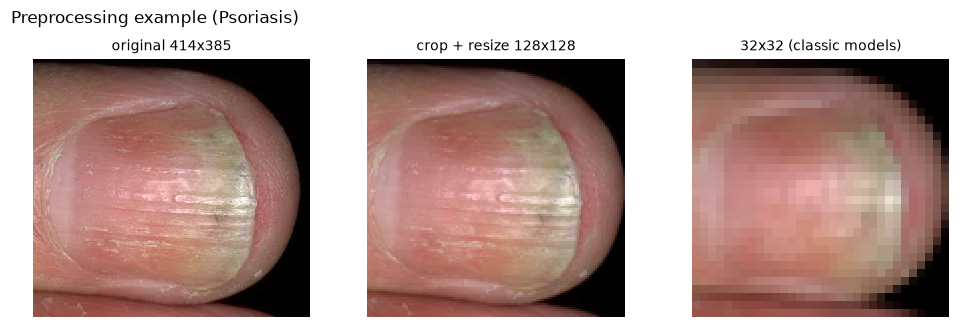

In [7]:
row = df[df["split"] == "train"].sample(1, random_state=SEED).iloc[0]
with Image.open(os.path.join(DATA_DIR, row["file"])) as im:
    im = im.convert("RGB")
    views = [(im, f"original {im.size[0]}x{im.size[1]}"),
             (square(im).resize((128, 128)), "crop + resize 128x128"),
             (square(im).resize((32, 32)), "32x32 (classic models)")]
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, (v, t) in zip(axes, views):
    ax.imshow(v, interpolation="nearest"); ax.set_title(t, fontsize=9); ax.axis("off")
fig.suptitle(f"Preprocessing example ({SHORT[row['label']]})", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); save(fig, "r2_preprocessing.png"); plt.show()

## 8. Unsupervised analysis: k-means clustering

**Question:** without using any labels, do the images naturally group by disease?

**Method** (training images only, so the test set stays untouched):
1. Each image → 32×32 pixels → 3,072 numbers.
2. **Standardise** (each feature mean 0, std 1) so no colour channel dominates.
3. **PCA** to 50 components: removes noise and makes k-means faster and more stable in high dimensions.
4. **k-means** for k = 2…10, choosing k with the elbow and silhouette score, then k = 5 (one per disease) to compare clusters against the true labels.
5. Agreement with the labels measured with **Adjusted Rand Index (ARI)** and **Normalised Mutual Information (NMI)**: 0 = no better than random, 1 = perfect match.

PCA: 3072 pixel features -> 50 components, keeping 88.1% of the variance


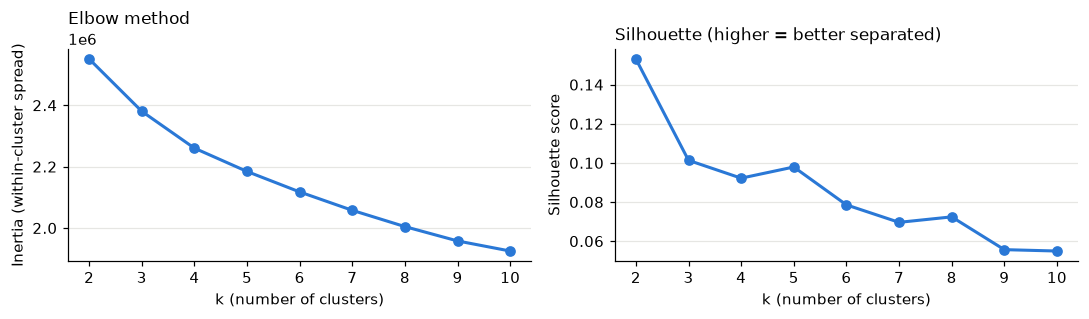

Best silhouette at k = 2 (score 0.153)


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

tr = (meta["split"] == "train").values
n = tr.sum()
X32 = X64[tr].reshape(n, 32, 2, 32, 2, 3).mean(axis=(2, 4)).reshape(n, -1)   # 64x64 -> 32x32
y_tr = meta.loc[tr, "label"].values
tone_tr = meta.loc[tr, "fitzpatrick_scale"].values

Xs = StandardScaler().fit_transform(X32)
n_comp = min(50, n - 1)
pca = PCA(n_components=n_comp, random_state=SEED)
Z = pca.fit_transform(Xs)
print(f"PCA: {X32.shape[1]} pixel features -> {n_comp} components, "
      f"keeping {100 * pca.explained_variance_ratio_.sum():.1f}% of the variance")

ks = list(range(2, min(10, n - 1) + 1))
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Z, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(ks, inertia, color="#2a78d6", linewidth=2, marker="o", markersize=6)
axes[0].set_xlabel("k (number of clusters)"); axes[0].set_ylabel("Inertia (within-cluster spread)")
axes[0].set_title("Elbow method", loc="left", fontsize=11)
axes[1].plot(ks, sil, color="#2a78d6", linewidth=2, marker="o", markersize=6)
axes[1].set_xlabel("k (number of clusters)"); axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette (higher = better separated)", loc="left", fontsize=11)
for ax in axes:
    ax.yaxis.grid(True, color="#e6e6e3"); ax.set_axisbelow(True)
fig.tight_layout(); save(fig, "r2_kmeans_choose_k.png"); plt.show()
best_k = ks[int(np.argmax(sil))]
print(f"Best silhouette at k = {best_k} (score {max(sil):.3f})")

k-means with k = 5: how well do the clusters match...


,ARI,NMI
clusters vs DISEASE,0.002,0.021
clusters vs SKIN TONE,0.014,0.026


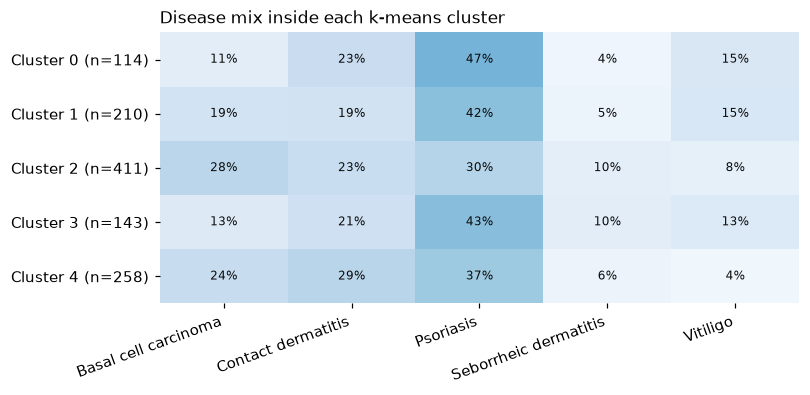

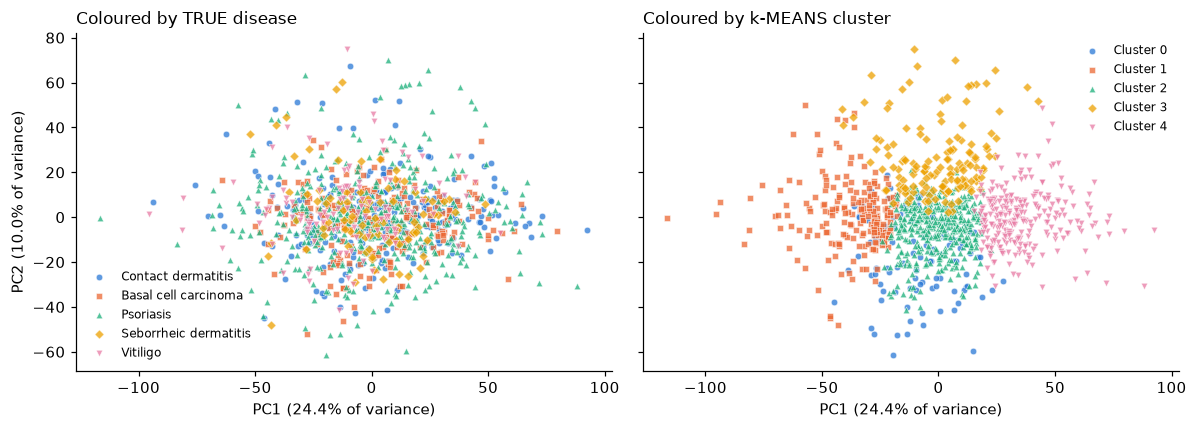

Correlation of PC1 with image brightness: r = 1.00


In [9]:
K = min(len(CLASS_NAMES), n - 1)
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Z)
clusters = km.labels_

tone_group = pd.cut(pd.Series(tone_tr), [-2, 0, 2, 4, 6],
                    labels=["unknown", "light", "medium", "dark"]).astype(str).values
scores = pd.DataFrame({
    "ARI": [adjusted_rand_score(y_tr, clusters), adjusted_rand_score(tone_group, clusters)],
    "NMI": [normalized_mutual_info_score(y_tr, clusters), normalized_mutual_info_score(tone_group, clusters)]},
    index=["clusters vs DISEASE", "clusters vs SKIN TONE"]).round(3)
print(f"k-means with k = {K}: how well do the clusters match...")
display(scores)

# Which diseases end up in which cluster (% of each cluster)
ct = pd.crosstab(pd.Series(clusters, name="cluster"), pd.Series(y_tr, name="disease").map(SHORT),
                 normalize="index") * 100
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.imshow(ct.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(ct.shape[1]), ct.columns, rotation=20, ha="right")
ax.set_yticks(range(ct.shape[0]), [f"Cluster {i} (n={(clusters == i).sum()})" for i in ct.index])
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        v = ct.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=8,
                color="white" if v > 60 else "#0b0b0b")
ax.set_title("Disease mix inside each k-means cluster", loc="left", fontsize=11)
ax.spines[:].set_visible(False)
save(fig, "r2_kmeans_clusters.png"); plt.show()

# 2-D picture: first two PCA components, coloured by true disease vs by cluster
markers = ["o", "s", "^", "D", "v"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for i, c in enumerate(CLASS_NAMES):
    m = y_tr == c
    axes[0].scatter(Z[m, 0], Z[m, 1], s=18, marker=markers[i], color=COLOURS[c], alpha=0.75,
                    edgecolor="white", linewidth=0.4, label=SHORT[c])
axes[0].legend(fontsize=8, frameon=False, loc="best")
axes[0].set_title("Coloured by TRUE disease", loc="left", fontsize=11)
greys = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
for k in range(K):
    m = clusters == k
    axes[1].scatter(Z[m, 0], Z[m, 1], s=18, marker=markers[k % 5], color=greys[k % 5], alpha=0.75,
                    edgecolor="white", linewidth=0.4, label=f"Cluster {k}")
axes[1].legend(fontsize=8, frameon=False, loc="best")
axes[1].set_title("Coloured by k-MEANS cluster", loc="left", fontsize=11)
for ax in axes:
    ax.set_xlabel(f"PC1 ({100 * pca.explained_variance_ratio_[0]:.1f}% of variance)")
axes[0].set_ylabel(f"PC2 ({100 * pca.explained_variance_ratio_[1]:.1f}% of variance)")
fig.tight_layout(); save(fig, "r2_pca_scatter.png"); plt.show()

# What does PC1 capture? Compare it with image brightness
r_pc1 = np.corrcoef(Z[:, 0], meta.loc[tr, "brightness"])[0, 1]
print(f"Correlation of PC1 with image brightness: r = {r_pc1:.2f}")

## 9. Key findings

The cell below prints the numbers to quote in the report and viva.

In [10]:
c = df["label"].value_counts()
g = (100 * groups.value_counts(normalize=True)).round(0)
lines = [
    f"* Final dataset: {len(df)} images, 5 diseases, split {', '.join(f'{k} {v}' for k, v in df['split'].value_counts()[['train','val','test']].items())}.",
    f"* Cleaning removed {len(removed)} images: " + ", ".join(f"{v} {k}" for k, v in removed['reason_group'].value_counts().items()) + ".",
    f"* Classes are imbalanced: {SHORT[c.idxmax()]} {c.max()} vs {SHORT[c.idxmin()]} {c.min()} ({c.max() / c.min():.1f}x) -> macro-F1 + class weights.",
    f"* Skin tone: {g.get('Light (I-II)', 0):.0f}% light, {g.get('Medium (III-IV)', 0):.0f}% medium, {g.get('Dark (V-VI)', 0):.0f}% dark (types I-II / III-IV / V-VI)"
    + (" -> dark skin under-represented." if g.get('Dark (V-VI)', 0) < 20 else "."),
    f"* Share of images from Atlas Dermatologico (watermarked) per disease: "
    + ", ".join(f"{k} {v:.0f}%" for k, v in src['% from Atlas'].items()) + ".",
    f"* Skin type vs image brightness: r = {r:.2f}.",
    f"* k-means (k = {K}) on raw pixels matches disease labels poorly (ARI {scores.loc['clusters vs DISEASE','ARI']}, NMI {scores.loc['clusters vs DISEASE','NMI']}); "
    f"vs skin tone ARI {scores.loc['clusters vs SKIN TONE','ARI']}, NMI {scores.loc['clusters vs SKIN TONE','NMI']}. PC1 vs brightness r = {r_pc1:.2f}.",
]
print("\n".join(lines))

* Final dataset: 1623 images, 5 diseases, split train 1136, val 243, test 244.
* Cleaning removed 46 images: 39 wrong disease in source folder, 6 duplicate of another image, 1 dataset QC: wrongly labelled.
* Classes are imbalanced: Psoriasis 604 vs Seborrheic dermatitis 123 (4.9x) -> macro-F1 + class weights.
* Skin tone: 50% light, 37% medium, 13% dark (types I-II / III-IV / V-VI) -> dark skin under-represented.
* Share of images from Atlas Dermatologico (watermarked) per disease: Basal cell carcinoma 72%, Contact dermatitis 11%, Psoriasis 17%, Seborrheic dermatitis 40%, Vitiligo 27%.
* Skin type vs image brightness: r = -0.25.
* k-means (k = 5) on raw pixels matches disease labels poorly (ARI 0.002, NMI 0.021); vs skin tone ARI 0.014, NMI 0.026. PC1 vs brightness r = 1.00.


**How to read the clustering result:** if ARI/NMI against disease are close to 0, raw pixel colours alone don't separate the diseases. The images group mostly by overall colour and lighting (see the PC1–brightness correlation), which partly reflects skin tone. That motivates the later sections: supervised models (R3), and CNNs (R4) that learn shapes and textures instead of raw colour.